# Neural Networks

## Introduction

In this report we use simple neural networks to segment MR images, following Chapter 4 of the book. Each pixel is classified as foreground ($l = 1$) or background ($l = 0$) by a model of the form

$$p(l = 1 \mid \mathbf{x}, \boldsymbol{\theta}) = \sigma\Big(\sum_{m=1}^{M} w_m \phi_m(\mathbf{x})\Big), \qquad \sigma(a) = \frac{1}{1 + e^{-a}},$$

with $M = 6$ basis functions. The parameters are trained by minimising the cross-entropy (Eq. 4.7) with stochastic gradient descent (Eq. 4.8), using $N' = 200$ samples per iteration, step size $\nu' = 0.005$ and 5000 iterations; the gradient is approximated by finite differences.

* **Task 1:** pixel-wise classifier with fixed cosine basis functions.
* **Task 2:** robustness of this classifier to an intensity transformation of the test image.
* **Task 3:** adaptive basis functions (Eq. 4.9), i.e. a neural network with one hidden layer.
* **Task 4:** the intensity of the neighbouring pixel as a second input feature, to segment a thin border.

The segmentations are compared with manual segmentations using the Dice coefficient.

<font size="5">Initialization</font>

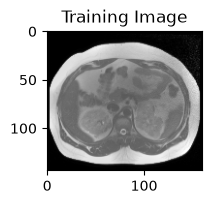

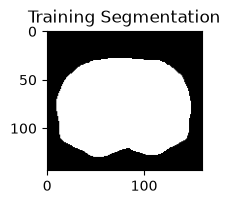

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io

M = 6
noOfSamples = 200
vm = 0.005
numIter = 5000

# Load data
clip0 = np.load('dataForNN_inside_clip0.npy', allow_pickle=True).tolist()

TI = clip0['trainingImage']
TS = clip0['trainingSegmentation']
TestI = clip0['testImage']
TestS = clip0['testSegmentation']

# Show image
plt.figure(figsize=(2,2))
plt.imshow(clip0['trainingImage'], cmap='gray')
plt.title('Training Image')
plt.show()

plt.figure(figsize=(2,2))
plt.imshow(clip0['trainingSegmentation'], cmap='gray')
plt.title('Training Segmentation')
plt.show()

## Task 1: Pixel-wise logistic regression classifier

For the data file ```dataForNN_inside_clip0.mat``` implement a pixel-wise logistic regression classifier $p(l \vert d, \theta)$, using fixed basis functions of the form

$$ \phi_m (d) = \cos[\pi(m-1)d] $$

You can use $\hat{w}_m = 0, \forall m$ for initializing the stochastic gradient descent algorithm.

Include in your report:
- a plot of the evolution of the cross-entropy across iterations
- the final segmentation of the test image
- the quantity $a$ and the obtained classifier (as in figure ...)
- visualization of where training samples are located (e.g. show $N^{\prime}$ samples of the last iteration of the stochastic gradient descent algorithm)

> ***Hints:***
> - getInputFeatures() provides images patches as input features based on ```numberOfNeighbors```
> - getSamples() collects sample data
> - showLocationOfSamples() plots the collected sample data
> - def plotSeg() overlays a segmentation on top of an image
>
> - for the sake of simplicity, you should compute the gradient $\nabla E_{N^{\prime}}(\theta)$ using the method of infinite differences. E.g. 
>       
>       gradient[n] = (newCost - cost[i]) / delta
>
>   computes the gradient for the $i^{th}$ iteration for the $n^{th}$ theta parameter 


### Theoretical Background: Pixel-Wise Logistic Regression

In Task 1, we formulate image segmentation as a pixel-wise binary classification problem. Given an input pixel with scalar intensity $d \in [0, 1]$, our goal is to estimate the posterior probability $p(l = 1 \mid d, \boldsymbol{\theta})$ that the pixel belongs to the foreground ($l = 1$) rather than the background ($l = 0$).

To allow for non-linear decision boundaries in the intensity domain, the input intensity $d$ is mapped into an $M$-dimensional feature space ($M = 6$) using a set of fixed cosine basis functions:

$$\phi_m(d) = \cos\big[\pi(m - 1)d\big], \quad m = 1, \dots, M$$

Note that for $m = 1$, $\phi_1(d) = \cos(0) = 1$, which serves as a constant bias term.

The model computes a linear activation $a(d; \boldsymbol{\theta})$ as a weighted combination of these basis functions, parameterized by the weight vector $\boldsymbol{\theta} = \mathbf{w} = [w_1, \dots, w_M]^T$:

$$a(d; \boldsymbol{\theta}) = \sum_{m=1}^{M} w_m \phi_m(d) = \boldsymbol{\phi}(d)^T \mathbf{w}$$

This activation is transformed into a valid probability via the logistic sigmoid function $\sigma(\cdot)$:

$$y(d; \boldsymbol{\theta}) = p(l = 1 \mid d, \boldsymbol{\theta}) = \sigma\big(a(d; \boldsymbol{\theta})\big) = \frac{1}{1 + e^{-a(d; \boldsymbol{\theta})}}$$

#### Parameter Optimization via Stochastic Gradient Descent
To optimize the parameter vector $\boldsymbol{\theta}$ against the ground-truth training labels $t_n \in \{0, 1\}$, we minimize the cross-entropy (Eq. 4.7), i.e. the negative log-likelihood of the Bernoulli model $p(t \mid d, \boldsymbol{\theta}) = y^t (1-y)^{1-t}$. At each iteration $i$, a balanced mini-batch of $N' = 200$ pixels (100 foreground and 100 background pixels) is randomly sampled from the training image, yielding the objective function:


$$E_{N'}(\boldsymbol{\theta}) = -\sum_{n=1}^{N'} \Big[ t_n \ln y_n + (1 - t_n) \ln(1 - y_n) \Big]$$

where $y_n = y(d_n; \boldsymbol{\theta})$. Starting from $\mathbf{w}^{(0)} = \mathbf{0}$, the weights are updated iteratively using stochastic gradient descent (SGD) with learning rate $\nu'$:

$$\boldsymbol{\theta}^{(i+1)} = \boldsymbol{\theta}^{(i)} - \nu' \nabla E_{N'}(\boldsymbol{\theta}^{(i)})$$

Each partial derivative component of the gradient vector $\nabla E_{N'}(\boldsymbol{\theta})$ is approximated numerically using the method of finite differences with a small step perturbation $\delta$:

$$\frac{\partial E_{N'}}{\partial \theta_m} \approx \frac{E_{N'}(\boldsymbol{\theta} + \delta \mathbf{e}_m) - E_{N'}(\boldsymbol{\theta})}{\delta}$$

where $\mathbf{e}_m$ is the $m$-th standard unit vector. Once trained, the model is applied to every pixel in the unseen test image, assigning a pixel to the foreground if $p(l = 1 \mid d, \boldsymbol{\theta}) \ge 0.5$ (equivalently, $a(d; \boldsymbol{\theta}) \ge 0$).

Note that $E_{N'}$ is a sum (not an average) over the $N'$ samples, as in Eq. (4.7). The step size $\nu' = 0.005$ is chosen for this definition: averaging instead would divide the gradient, and thus every update, by $N' = 200$.

The following functions are provided:

    getInputFeatures(), getSamples(), showLocationOfSamples(), plotSeg()

In [2]:
def getInputFeatures(image, numberOfNeighbors, shift=1):
    numberOfFeatures = numberOfNeighbors + 1

    leftNeighborImage = np.zeros_like(image)
    leftNeighborImage[:, shift:] = image[:, :-shift]

    rightNeighborImage = np.zeros_like(image)
    rightNeighborImage[:, :-shift] = image[:, shift:]

    topNeighborImage = np.zeros_like(image)
    topNeighborImage[shift:, :] = image[:-shift, :]

    bottomNeighborImage = np.zeros_like(image)
    bottomNeighborImage[:-shift, :] = image[shift:, :]

    leftTopNeighborImage = np.zeros_like(image)
    leftTopNeighborImage[shift:, shift:] = image[:-shift, :-shift]

    rightTopNeighborImage = np.zeros_like(image)
    rightTopNeighborImage[shift:, :-shift] = image[:-shift, shift:]

    leftBottomNeighborImage = np.zeros_like(image)
    leftBottomNeighborImage[:-shift, shift:] = image[shift:, :-shift]

    rightBottomNeighborImage = np.zeros_like(image)
    rightBottomNeighborImage[:-shift, :-shift] = image[shift:, shift:]

    if numberOfNeighbors == 0:
        features = image.ravel()
    elif numberOfNeighbors == 1:
        features = np.column_stack((image.ravel(), bottomNeighborImage.ravel()))
    elif numberOfNeighbors == 4:
        features = np.column_stack((
            image.ravel(),
            leftNeighborImage.ravel(),
            rightNeighborImage.ravel(),
            topNeighborImage.ravel(),
            bottomNeighborImage.ravel()
        ))
    elif numberOfNeighbors == 8:
        features = np.column_stack((
            image.ravel(),
            leftTopNeighborImage.ravel(),
            topNeighborImage.ravel(),
            rightTopNeighborImage.ravel(),
            leftNeighborImage.ravel(),
            rightNeighborImage.ravel(),
            leftBottomNeighborImage.ravel(),
            bottomNeighborImage.ravel(),
            rightBottomNeighborImage.ravel()
        ))
    else:
        raise NotImplementedError("Number of neighbors not implemented yet")

    featureImage = features.reshape((image.shape[0], image.shape[1], numberOfFeatures))
    return featureImage

def getSamples(featureImage, segmentation, numberOfSamples, mask=None):
    if mask is None:
        mask = np.ones(segmentation.shape)

    numberOfFeatures = featureImage.shape[2]
    numberOfPixels = featureImage.shape[0] * featureImage.shape[1]

    numberOfSamplesPerClass = int(np.ceil(numberOfSamples / 2))
    x = np.zeros((numberOfSamplesPerClass, numberOfFeatures, 2))
    t = np.zeros((numberOfSamplesPerClass, 2))
    rowAndColNumbers = np.zeros((numberOfSamplesPerClass, 2, 2))

    oneHotEncoding = np.zeros((segmentation.shape[0], segmentation.shape[1], 2))
    oneHotEncoding[:, :, 0] = segmentation
    oneHotEncoding[:, :, 1] = 1 - segmentation

    rows, cols = np.meshgrid(np.arange(1, featureImage.shape[0] + 1),
                             np.arange(1, featureImage.shape[1] + 1))

    for k in range(2):
        indices = np.where(oneHotEncoding[:, :, k] * mask)
        sampleIndices = np.random.choice(len(indices[0]), numberOfSamplesPerClass, replace=False)
        indices = (indices[0][sampleIndices], indices[1][sampleIndices])

        x[:, :, k] = featureImage[indices[0], indices[1]]
        t[:, k] = segmentation[indices[0], indices[1]]
        rowAndColNumbers[:, :, k] = np.stack((indices[0], indices[1]), axis=1)

    x = np.concatenate((x[:, :, 0], x[:, :, 1]), axis=0)
    t = np.concatenate((t[:, 0], t[:, 1]), axis=0)
    rowAndColNumbers = np.concatenate((rowAndColNumbers[:, :, 0], rowAndColNumbers[:, :, 1]), axis=0)

    x = x[:numberOfSamples, :]
    t = t[:numberOfSamples]
    rowAndColNumbers = rowAndColNumbers[:numberOfSamples, :]

    return x, t, rowAndColNumbers

def showLocationOfSamples(image, rowAndColNumbers, t):
    colors = ['b', 'r']
    markers = ['o', 'x']

    plt.imshow(image, cmap='gray')
    T = np.zeros([rowAndColNumbers.shape[0], 2])
    T[:,0] = t
    T[:,1] = t-1
    for k in range(2):
        tmp = rowAndColNumbers[np.where(T[:, k]), :]
        marker = markers[k]
        color = colors[k]
        plt.scatter(tmp[:,:,1], tmp[:,:,0], marker=marker, color=color, linewidth=0.75)
    
    plt.show

def plotSeg(image, segmentation):
    tmp = np.zeros((segmentation.shape[0], segmentation.shape[1], 3))
    tmp[:, :, 0] = 1 - segmentation
    tmp[:, :, 2] = segmentation
    plt.imshow(image, cmap='gray')
    plt.imshow(tmp, alpha = 0.5)

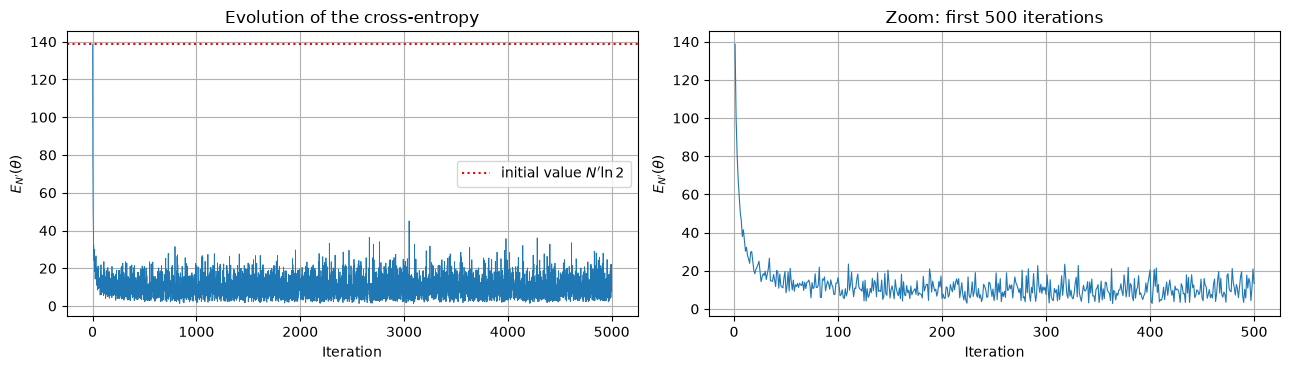

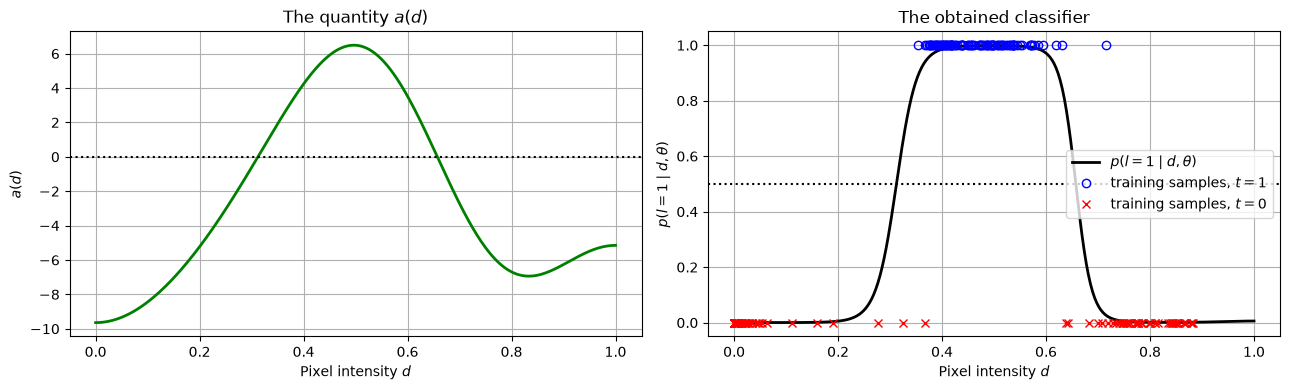

Decision boundaries (a(d) = 0) at d = [0.31 0.66]


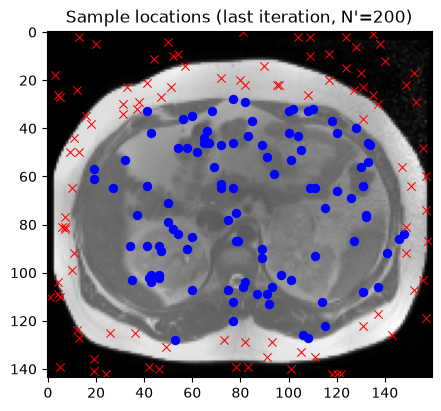

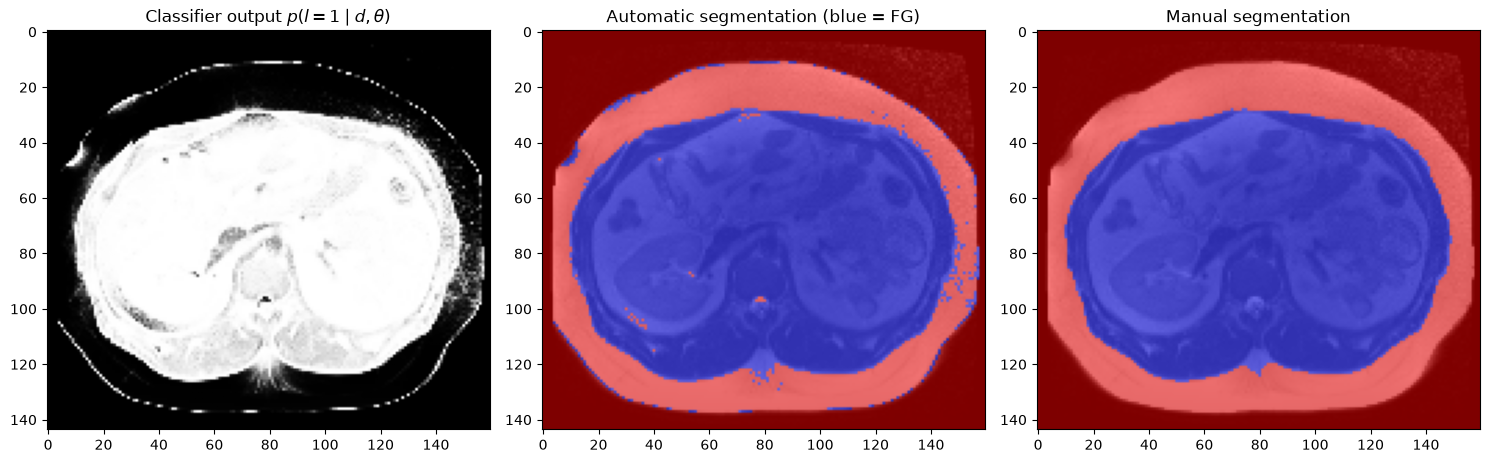

Dice coefficient (test image): 0.981


In [3]:
# Helper functions for Task 1
def compute_basis_fixed(x, M=6):
    """
    x: array of shape (N, 1) or (N,) with pixel intensities
    Returns Phi of shape (N, M) where phi_m(d) = cos(pi * (m - 1) * d)
    """
    d = x.reshape(-1, 1)  # (N, 1)
    m = np.arange(1, M + 1).reshape(1, -1)  # (1, M)
    return np.cos(np.pi * (m - 1) * d)

def sigmoid(a):
    # Clip 'a' to prevent overflow in exp(-a)
    a_clipped = np.clip(a, -500, 500)
    return 1.0 / (1.0 + np.exp(-a_clipped))

def compute_loss_fixed(Phi, t, w):
    a = Phi @ w
    y = sigmoid(a)
    eps = 1e-12
    loss = -np.sum(t * np.log(y + eps) + (1.0 - t) * np.log(1.0 - y + eps))
    return loss

featureImage = getInputFeatures(TI, numberOfNeighbors=0)
w = np.zeros(M)          # Initialize w_m = 0 for all m
delta = 1e-5             # Step size for finite differences
cost = np.zeros(numIter) # Track cross-entropy across iterations

# Stochastic Gradient Descent 
np.random.seed(42) # Optional: for reproducible results

for i in range(numIter):
    # Draw N' = 200 new samples (100 foreground, 100 background)
    x_batch, t_batch, rowAndColNumbers = getSamples(featureImage, TS, noOfSamples)
    Phi_batch = compute_basis_fixed(x_batch, M)
    
    # Current batch loss
    cost[i] = compute_loss_fixed(Phi_batch, t_batch, w)
    
    # Compute gradient via finite differences
    gradient = np.zeros(M)
    for n in range(M):
        w_perturbed = w.copy()
        w_perturbed[n] += delta
        newCost = compute_loss_fixed(Phi_batch, t_batch, w_perturbed)
        gradient[n] = (newCost - cost[i]) / delta
        
    # Update weights
    w = w - vm * gradient

# ---------- Visualizations ----------
# (a) Evolution of the cross-entropy
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(cost, linewidth=0.6)
axes[0].axhline(noOfSamples * np.log(2), color='r', linestyle=':', label=r"initial value $N'\ln 2$")
axes[0].set_title('Evolution of the cross-entropy')
axes[0].set_xlabel('Iteration'); axes[0].set_ylabel(r"$E_{N'}(\theta)$")
axes[0].legend(); axes[0].grid(True)
axes[1].plot(np.arange(1, 501), cost[:500], linewidth=0.8)
axes[1].set_title('Zoom: first 500 iterations')
axes[1].set_xlabel('Iteration'); axes[1].set_ylabel(r"$E_{N'}(\theta)$")
axes[1].grid(True)
plt.tight_layout(); plt.show()

# (b) The quantity a(d) and the obtained classifier p(l=1|d) (as in Fig. 4.2 d-e)
d_grid = np.linspace(0, 1, 500)
a_grid = compute_basis_fixed(d_grid, M) @ w
p_grid = sigmoid(a_grid)
d_batch = x_batch[:, 0]
fg, bg = t_batch == 1, t_batch == 0

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(d_grid, a_grid, 'g', linewidth=2)
axes[0].axhline(0, color='k', linestyle=':')
axes[0].set_title('The quantity $a(d)$')
axes[0].set_xlabel('Pixel intensity $d$'); axes[0].set_ylabel('$a(d)$'); axes[0].grid(True)

axes[1].plot(d_grid, p_grid, 'k', linewidth=2, label=r'$p(l=1 \mid d, \theta)$')
axes[1].axhline(0.5, color='k', linestyle=':')
axes[1].plot(d_batch[fg], t_batch[fg], 'bo', mfc='none', label='training samples, $t=1$')
axes[1].plot(d_batch[bg], t_batch[bg], 'rx', label='training samples, $t=0$')
axes[1].set_title('The obtained classifier')
axes[1].set_xlabel('Pixel intensity $d$'); axes[1].set_ylabel(r'$p(l=1 \mid d, \theta)$')
axes[1].legend(loc='center right'); axes[1].grid(True)
plt.tight_layout(); plt.show()

edges = d_grid[np.flatnonzero(np.diff((a_grid > 0).astype(int)))]
print('Decision boundaries (a(d) = 0) at d =', np.round(edges, 2))

# (c) Location of the N' training samples of the last iteration
plt.figure(figsize=(5, 4.5))
showLocationOfSamples(TI, rowAndColNumbers, t_batch)
plt.title(f"Sample locations (last iteration, N'={noOfSamples})")
plt.show()

# (d) Final segmentation of the test image
test_features = getInputFeatures(TestI, numberOfNeighbors=0)
Phi_test = compute_basis_fixed(test_features.reshape(-1, 1), M)
prob_map_test = sigmoid(Phi_test @ w).reshape(TestI.shape)
pred_seg_test = (prob_map_test >= 0.5).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(prob_map_test, cmap='gray', vmin=0, vmax=1)
axes[0].set_title(r'Classifier output $p(l=1 \mid d, \theta)$')
plt.sca(axes[1]); plotSeg(TestI, pred_seg_test)
axes[1].set_title('Automatic segmentation (blue = FG)')
plt.sca(axes[2]); plotSeg(TestI, TestS)
axes[2].set_title('Manual segmentation')
plt.tight_layout(); plt.show()

dice = 2 * np.sum(pred_seg_test * TestS) / (pred_seg_test.sum() + TestS.sum())
print(f'Dice coefficient (test image): {dice:.3f}')

### Results and Discussion for Task 1

* **Convergence of stochastic gradient descent:** With $\mathbf{w} = \mathbf{0}$ the classifier outputs $y = 0.5$ for every pixel, so the cross-entropy starts at $N' \ln 2 \approx 139$. It drops very quickly, to below 20 within the first ~50 iterations, and stabilizes around $E_{N'} \approx 10$ after a few hundred iterations, well before training ends at 5000 iterations. The remaining fluctuations are expected, because $N' = 200$ new pixels are drawn in every iteration: a batch that contains a few pixels close to the decision boundary gives a higher cost than one that does not. The cross-entropy does not reach zero because a small number of foreground and background pixels have overlapping intensities.

* **The quantity $a(d)$ and the classifier:** The learned activation $a(d) = \sum_m w_m \phi_m(d)$ is positive only for intermediate intensities, crossing zero at $d \approx 0.31$ and $d \approx 0.66$. The classifier is therefore a *band-pass* in intensity: pixels with $0.31 < d < 0.66$ (the organs inside the abdomen) are labelled foreground, while both darker pixels (air outside the body) and brighter pixels (the subcutaneous fat layer) are labelled background. This explains why non-linear basis functions are needed: a model that is linear in $d$, $a(d) = w_1 + w_2 d$, has a single threshold and could never separate a class that lies *between* two parts of the other class.

  Since the two classes are almost perfectly separable in intensity, minimizing the cross-entropy drives $|a|$ to large values (up to $\approx 6$ inside the band and $\approx -10$ outside). The sigmoid therefore saturates, and the classifier becomes nearly a step function: $p \approx 1$ inside the band and $p \approx 0$ outside, with sharp transitions at the two decision boundaries. The training samples of the last iteration confirm this: almost all blue samples ($t = 1$) lie inside the band and almost all red samples ($t = 0$) outside it, with only a handful of samples in the overlap region near the boundaries.

* **Location of the training samples:** `getSamples()` draws a balanced batch of 100 foreground pixels (blue circles inside the abdominal cavity) and 100 background pixels (red crosses). The background samples fall in two very different regions: the dark air around the patient and the bright fat layer under the skin. These correspond to the two intensity ranges outside the band.

* **Segmentation of the test image:** Applied to the unseen test image, the classifier separates the abdominal interior from the surrounding fat and air very well, with a Dice coefficient of **0.98** compared to the manual segmentation. The remaining errors are mainly:
  * a thin ring of false positives at the outer edge of the body, where pixels contain a mixture of fat and air (partial-volume effect) and therefore have an intermediate intensity that falls inside the band;
  * scattered false positives in the fat layer along the right side of the body, where the fat is slightly darker;
  * a few false negatives at bright structures inside the abdomen, such as the spinal canal.

  These errors cannot be avoided by a pixel-wise classifier, since the intensity of a single pixel carries no information about its spatial context. This motivates including neighbouring pixels as input features (Tasks 4 and 5).

## Task 2: Manipulate Intensities in Test Image

Create a new test image by replacing the intensities in the original test image using the rule
$$ d_{new} = d^{1.3}. $$

Use the classifier trained above to segment this new test image.

In your report, reflect on the result you obtain. Do the two test images look similar? What about their segmentations?

### Theoretical Background: Sensitivity to Intensity Transformations

In medical imaging, the intensity distribution of a scan can vary between acquisitions due to differences in scanner hardware, acquisition protocols or post-processing (e.g. gamma correction). To test how robust the pixel-wise classifier of Task 1 is to such variations, we apply a non-linear power-law (gamma) transformation to the unseen test image:

$$d_{\text{new}} = d^{1.3}$$

Since $d \in [0, 1]$, this transformation keeps the end points fixed ($0^{1.3} = 0$, $1^{1.3} = 1$) and is monotonic, so the *ordering* of intensities, and therefore all anatomical structures and edges, are preserved. All intermediate intensities are lowered ($d_{\text{new}} < d$ for $0 < d < 1$), e.g. $0.5 \rightarrow 0.41$ and $0.8 \rightarrow 0.75$, so the image becomes slightly darker. The local contrast also changes: the slope $\mathrm{d}d_{\text{new}}/\mathrm{d}d = 1.3\, d^{0.3}$ is smaller than 1 for $d < 0.42$ and larger than 1 above it, so differences between dark intensities are compressed while differences between bright intensities are stretched.

The classifier of Task 1 is applied without retraining. It labels a pixel as foreground when its intensity lies inside the band $0.31 < d < 0.66$, i.e. it relies on *absolute* intensity values. On the transformed image a pixel is therefore classified as foreground when $0.31 < d^{1.3} < 0.66$, which in terms of the *original* intensities corresponds to

$$0.31^{1/1.3} \approx 0.41 \;<\; d \;<\; 0.66^{1/1.3} \approx 0.72 .$$

The transformation thus effectively shifts the learned intensity band upwards by about $0.06$–$0.10$, and we expect errors at both of its ends.


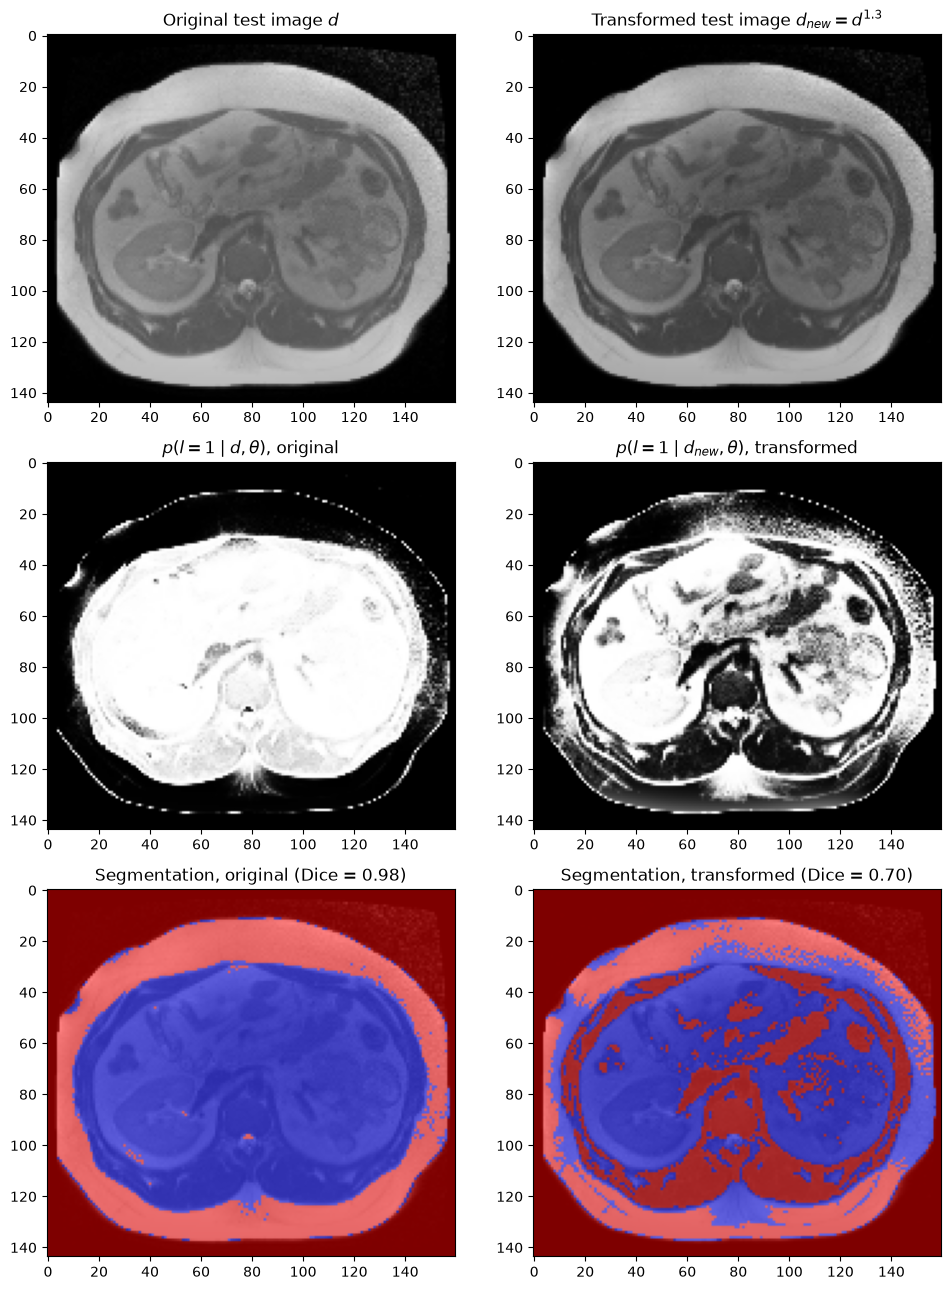

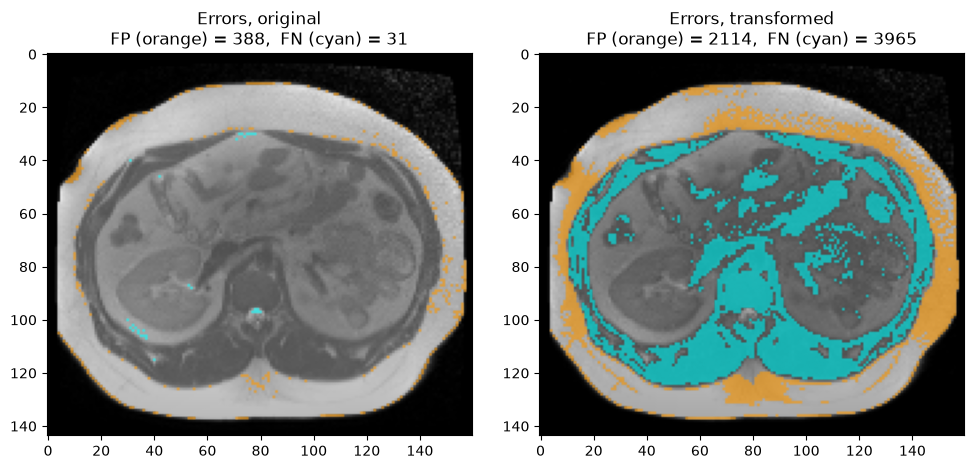

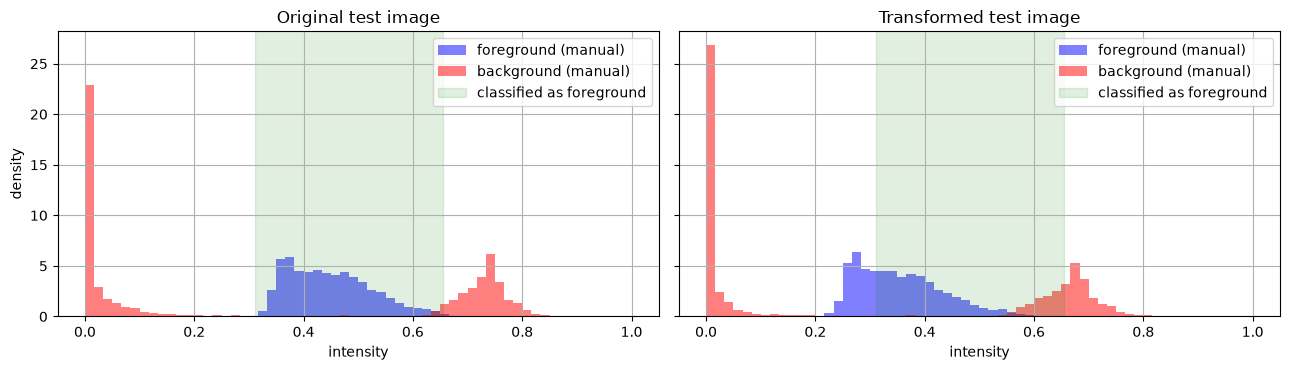

Decision boundaries of the classifier: d = [0.311 0.655]
Equivalent band in ORIGINAL intensities after the transform: d = [0.407 0.722]
Dice original: 0.981   Dice transformed: 0.701


In [4]:
TestI_new = TestI ** 1.3

def segmentWithTask1Classifier(image):
    features = getInputFeatures(image, numberOfNeighbors=0)
    Phi = compute_basis_fixed(features.reshape(-1, 1), M)
    prob = sigmoid(Phi @ w).reshape(image.shape)
    return prob, (prob >= 0.5).astype(float)

def diceScore(seg, ref):
    return 2 * np.sum(seg * ref) / (seg.sum() + ref.sum())

prob_orig, seg_orig = segmentWithTask1Classifier(TestI)
prob_new,  seg_new  = segmentWithTask1Classifier(TestI_new)

# Images, classifier outputs and segmentations side by side
fig, axes = plt.subplots(3, 2, figsize=(10, 13))
axes[0, 0].imshow(TestI, cmap='gray', vmin=0, vmax=1);     axes[0, 0].set_title('Original test image $d$')
axes[0, 1].imshow(TestI_new, cmap='gray', vmin=0, vmax=1); axes[0, 1].set_title(r'Transformed test image $d_{new} = d^{1.3}$')
axes[1, 0].imshow(prob_orig, cmap='gray', vmin=0, vmax=1); axes[1, 0].set_title(r'$p(l=1 \mid d, \theta)$, original')
axes[1, 1].imshow(prob_new, cmap='gray', vmin=0, vmax=1);  axes[1, 1].set_title(r'$p(l=1 \mid d_{new}, \theta)$, transformed')
plt.sca(axes[2, 0]); plotSeg(TestI, seg_orig)
axes[2, 0].set_title(f'Segmentation, original (Dice = {diceScore(seg_orig, TestS):.2f})')
plt.sca(axes[2, 1]); plotSeg(TestI_new, seg_new)
axes[2, 1].set_title(f'Segmentation, transformed (Dice = {diceScore(seg_new, TestS):.2f})')
plt.tight_layout(); plt.show()

# Error maps compared to the manual segmentation
def errorMap(seg, ref):
    err = np.zeros(seg.shape + (3,))
    err[(seg == 1) & (ref == 0)] = [1, 0.6, 0]   # false positive: orange
    err[(seg == 0) & (ref == 1)] = [0, 1, 1]     # false negative: cyan
    return err

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, img, seg, title in [(axes[0], TestI, seg_orig, 'Errors, original'),
                            (axes[1], TestI_new, seg_new, 'Errors, transformed')]:
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.imshow(errorMap(seg, TestS), alpha=0.6 * (errorMap(seg, TestS).sum(axis=2) > 0))
    fp, fn = np.sum((seg == 1) & (TestS == 0)), np.sum((seg == 0) & (TestS == 1))
    ax.set_title(f'{title}\nFP (orange) = {fp},  FN (cyan) = {fn}')
plt.tight_layout(); plt.show()

# Intensity histograms of the test image before and after the transformation
d_grid = np.linspace(0, 1, 500)
a_grid = compute_basis_fixed(d_grid, M) @ w
edges = d_grid[np.flatnonzero(np.diff((a_grid > 0).astype(int)))]   # decision boundaries of Task 1

bins = np.linspace(0, 1, 61)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, img, title in [(axes[0], TestI, 'Original test image'), (axes[1], TestI_new, 'Transformed test image')]:
    ax.hist(img[TestS == 1], bins=bins, density=True, alpha=0.5, color='b', label='foreground (manual)')
    ax.hist(img[TestS == 0], bins=bins, density=True, alpha=0.5, color='r', label='background (manual)')
    ax.axvspan(edges[0], edges[1], color='g', alpha=0.12, label='classified as foreground')
    ax.set_title(title); ax.set_xlabel('intensity'); ax.legend(); ax.grid(True)
axes[0].set_ylabel('density')
plt.tight_layout(); plt.show()

print('Decision boundaries of the classifier: d =', np.round(edges, 3))
print('Equivalent band in ORIGINAL intensities after the transform: d =', np.round(edges ** (1 / 1.3), 3))
print(f'Dice original: {diceScore(seg_orig, TestS):.3f}   Dice transformed: {diceScore(seg_new, TestS):.3f}')

### Results and Discussion for Task 2

* **Do the two test images look similar?** Yes. Visually, the original image $d$ and the transformed image $d^{1.3}$ are almost identical: the transformed image is slightly darker, but all anatomical structures, organ boundaries and their relative brightness are preserved. A human observer would segment both images in exactly the same way.

* **Do their segmentations look similar?** No. While the classifier reaches a Dice coefficient of **0.98** on the original test image, it drops to **0.70** on the transformed image. The error maps show that the number of false positives increases from 388 to 2114 and the number of false negatives from 31 to 3965. The errors occur at **both** ends of the learned intensity band:
  * **False negatives inside the abdomen (cyan).** The darker organs and tissues, such as large parts of the liver, the bowel and the back muscles around the spine, have original intensities around $0.35$–$0.41$. After the transformation they fall below the lower decision boundary ($0.384^{1.3} \approx 0.29 < 0.31$) and are classified as background. About 36 % of all foreground pixels have $d < 0.41$, which explains the large number of false negatives. Only the brighter organs, such as the kidneys, remain foreground.
  * **False positives in the fat layer (orange).** The darker part of the subcutaneous fat, with original intensities between $0.66$ and $0.72$, is pushed into the band (e.g. $0.72^{1.3} \approx 0.65 < 0.66$) and is wrongly classified as foreground, mainly along the inner side of the fat layer and at the flanks.

* **Explanation.** The histograms show what happens: the transformation moves both class distributions to the left, while the decision boundaries of the classifier stay at $d = 0.31$ and $d = 0.66$. In terms of the original intensities, the classifier now effectively accepts $0.41 < d < 0.72$ instead of $0.31 < d < 0.66$. Because the foreground and the fat lie directly next to the two boundaries, even this moderate shift causes many misclassifications on both sides.

* **Conclusion.** A pixel-wise intensity classifier learns *absolute* intensity thresholds that are only valid for images with the same intensity distribution as the training image. It is not invariant to (even monotonic) intensity transformations, although such transformations do not change the image content at all. In practice this can be addressed by intensity normalisation of the images before classification, by including images with varying contrast in the training data (data augmentation), or by models that use spatial context and local contrast instead of absolute intensities.

## Task 3: Adaptive Basis Functions

Now replace the fixed cosine basis functions in your model with adaptive ones of the type Eq. (4.9), and train the classifier again. The extra parameters $\beta_{m,j}$ can be initialized randomly, distributed according to a zero-mean Gaussian distribution with unit variance. For the trained model, visualize again the obtained classifier and the resulting segmentation of the original test image. This time, also include a plot of the estimated basis functions $\phi_m(d)$.



### Theoretical Background: Adaptive Basis Functions (a Neural Network with One Hidden Layer)

In Task 1 the basis functions $\phi_m(d) = \cos[\pi(m-1)d]$ were **fixed**: only their weights $w_m$ were learned, and their shape had to be chosen by hand beforehand. This works for a one-dimensional input, but it does not scale to higher-dimensional inputs: with 5 one-dimensional cosines and separable basis functions, a $3 \times 3$ patch ($D = 9$) would already require $5^9 \approx 2$ million basis functions ("curse of dimensionality"). The alternative is to use **adaptive** basis functions whose shape depends on extra parameters that are learned from the data together with the weights.

#### Model
Following Eq. (4.9), we keep one constant basis function and replace the other $M - 1 = 5$ by logistic functions of a linear combination of the input:

$$
\phi_m(d) =
\begin{cases}
1 & \text{if } m = 1, \\[4pt]
\sigma\big(\beta_{m,1}\, d + \beta_{m,0}\big) & \text{for } m = 2, \dots, M,
\end{cases}
$$

where $\sigma(\cdot)$ is the same logistic function as before. The classifier itself keeps the same form as in Task 1:

$$
p(l = 1 \mid d, \boldsymbol{\theta}) = \sigma\big(a(d)\big), \qquad a(d) = \sum_{m=1}^{M} w_m\, \phi_m(d).
$$

This model is a feed-forward **neural network** with one hidden layer (cf. Fig. 4.4): the input unit $d$ is linearly combined and passed through the logistic function in each of the $M - 1$ **hidden units** $\phi_m(d)$, and the hidden units are in turn linearly combined and passed through the logistic function in the **output unit** $f(d)$. The parameters $\beta_{m,0}$ and $w_1$ act as biases (connections to a unit clamped to 1).

The model now has $\boldsymbol{\theta} = \{w_1, \dots, w_M\} \cup \{\beta_{m,0}, \beta_{m,1}\}_{m=2}^{M}$, i.e. $6 + 2 \cdot 5 = 16$ parameters (compared to 6 in Task 1).

#### Interpretation of the basis functions
Each adaptive basis function is a smooth **step** in intensity:
* its transition is located at $d^{*}_m = -\beta_{m,0} / \beta_{m,1}$ (where $\phi_m = 0.5$);
* its steepness is set by $|\beta_{m,1}|$: the larger $|\beta_{m,1}|$, the sharper the step (the width of the transition is roughly $4 / |\beta_{m,1}|$);
* the sign of $\beta_{m,1}$ determines whether the step goes up ($\beta_{m,1} > 0$) or down ($\beta_{m,1} < 0$) with increasing intensity.

Instead of fixing the shapes in advance, training therefore moves and sharpens the steps so that they fall where the data needs them. For example, the band-pass classifier found in Task 1 can be built from only two steps, one rising at $d \approx 0.31$ and one falling at $d \approx 0.66$:
$a(d) \approx w_1 + w_2\, \sigma\big(k(d - 0.31)\big) - w_3\, \sigma\big(k(d - 0.66)\big)$. With $M - 1 = 5$ hidden units the model has more flexibility than strictly needed.

#### Training
Training is done exactly as in Task 1: we minimise the cross-entropy (Eq. 4.7)

$$
E_{N'}(\boldsymbol{\theta}) = -\sum_{n=1}^{N'} \Big[ t_n \ln f(d_n) + (1 - t_n) \ln\big(1 - f(d_n)\big) \Big]
$$

with stochastic gradient descent (Eq. 4.8, $N' = 200$, $\nu' = 0.005$, 5000 iterations), and approximate all 16 components of the gradient by forward finite differences.

Two differences with Task 1 are important:
* **Non-convex optimisation.** In Task 1, $a(d)$ was linear in the parameters, and the cross-entropy was a convex function of $\mathbf{w}$ with a single minimum. Now $a(d)$ depends non-linearly on the $\beta_{m,j}$, so $E_{N'}(\boldsymbol{\theta})$ is non-convex and can have several local minima. The solution found can therefore depend on the initialisation.
* **Random initialisation.** The weights are initialised as $w_m = 0$, but the $\beta_{m,j}$ are drawn from a zero-mean Gaussian with unit variance. If all $\beta_{m,j}$ started at the same value, all hidden units would be identical, receive identical gradients and remain identical during training, so the network would effectively have a single hidden unit. Random initialisation breaks this symmetry so that each hidden unit can learn a different step. Because $|\beta_{m,1}| \approx 1$ at the start, the initial basis functions are very smooth (almost linear over $[0, 1]$); training has to increase $|\beta_{m,1}|$ to make them steep enough to separate the classes.

#### What we visualise
For the trained model we show the evolution of the cross-entropy, the quantity $a(d)$ and the classifier $p(l = 1 \mid d, \boldsymbol{\theta})$ together with the training samples, the segmentation of the original test image, and the **learned basis functions** $\phi_m(d)$ for $m = 2, \dots, M$, together with their weights $w_m$. This shows how the network has built its decision rule out of the individual steps.

In [5]:
# Parameter vector theta = [w_1..w_M, beta_{2,0}, beta_{2,1}, ..., beta_{M,0}, beta_{M,1}]  (6 + 2*5 = 16)

def unpack(theta, M=6):
    w = theta[:M]                          
    beta = theta[M:].reshape(M - 1, 2)     
    return w, beta

def compute_basis_adaptive(d, beta):
    """
    d: array (N,) of intensities, beta: (M-1, 2)
    Returns Phi of shape (N, M): phi_1 = 1, phi_m = sigma(beta_{m,1} d + beta_{m,0}) for m = 2..M
    """
    d = d.reshape(-1, 1)                                   
    hidden = sigmoid(d * beta[:, 1] + beta[:, 0])          
    return np.hstack([np.ones((d.shape[0], 1)), hidden])   

def classifier_adaptive(theta, d):
    w, beta = unpack(theta, M)
    return sigmoid(compute_basis_adaptive(d, beta) @ w)

def compute_loss_adaptive(theta, d, t):
    y = classifier_adaptive(theta, d)
    eps = 1e-12
    return -np.sum(t * np.log(y + eps) + (1.0 - t) * np.log(1.0 - y + eps))

# Initialization: w = 0, beta ~ N(0, 1)
np.random.seed(42)
theta3 = np.concatenate([np.zeros(M), np.random.randn((M - 1) * 2)])
beta_init = unpack(theta3, M)[1].copy()        
delta = 1e-5
cost3 = np.zeros(numIter)
featureImage = getInputFeatures(TI, numberOfNeighbors=0)

# Stochastic gradient descent
for i in range(numIter):
    x_batch3, t_batch3, rowAndColNumbers3 = getSamples(featureImage, TS, noOfSamples)
    d_batch3 = x_batch3[:, 0]

    cost3[i] = compute_loss_adaptive(theta3, d_batch3, t_batch3)

    gradient = np.zeros_like(theta3)
    for n in range(theta3.size):
        theta_perturbed = theta3.copy()
        theta_perturbed[n] += delta
        newCost = compute_loss_adaptive(theta_perturbed, d_batch3, t_batch3)
        gradient[n] = (newCost - cost3[i]) / delta

    theta3 = theta3 - vm * gradient

w3, beta3 = unpack(theta3, M)
print('Weights w_1..w_M:', np.round(w3, 2))
print('\n m   beta_m0   beta_m1   step location -beta_m0/beta_m1   w_m')
for m in range(2, M + 1):
    b0, b1 = beta3[m - 2]
    print(f'{m:2d}  {b0:8.2f}  {b1:8.2f}  {-b0 / b1:12.3f}                  {w3[m - 1]:7.2f}')

Weights w_1..w_M: [ -3.63  -5.51  16.44  -4.47  -3.33 -13.47]

 m   beta_m0   beta_m1   step location -beta_m0/beta_m1   w_m
 2     -3.70      4.88         0.759                    -5.51
 3     -4.96     15.37         0.323                    16.44
 4     -3.00      3.78         0.792                    -4.47
 5      1.46      0.75        -1.952                    -3.33
 6     -8.37     12.45         0.672                   -13.47


### Visualizations for Task 3
Below we show (a) the evolution of the cross-entropy, compared with Task 1; (b) the basis functions $\phi_m(d)$ before and after training, and weighted by their coefficients $w_m$, which shows how $a(d)$ is built up; (c) the quantity $a(d)$ and the obtained classifier, together with the training samples of the last iteration and the Task 1 classifier for comparison; and (d) the segmentation of the original test image.

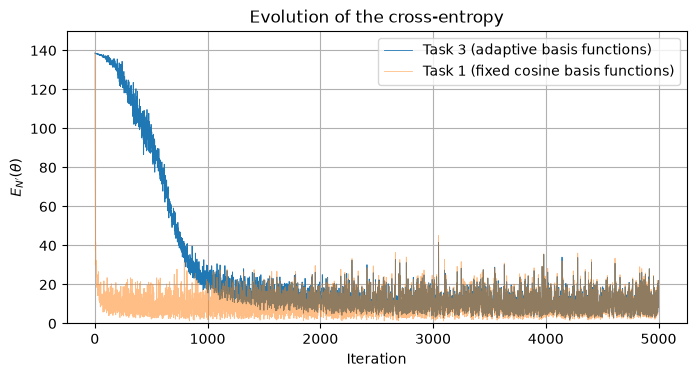

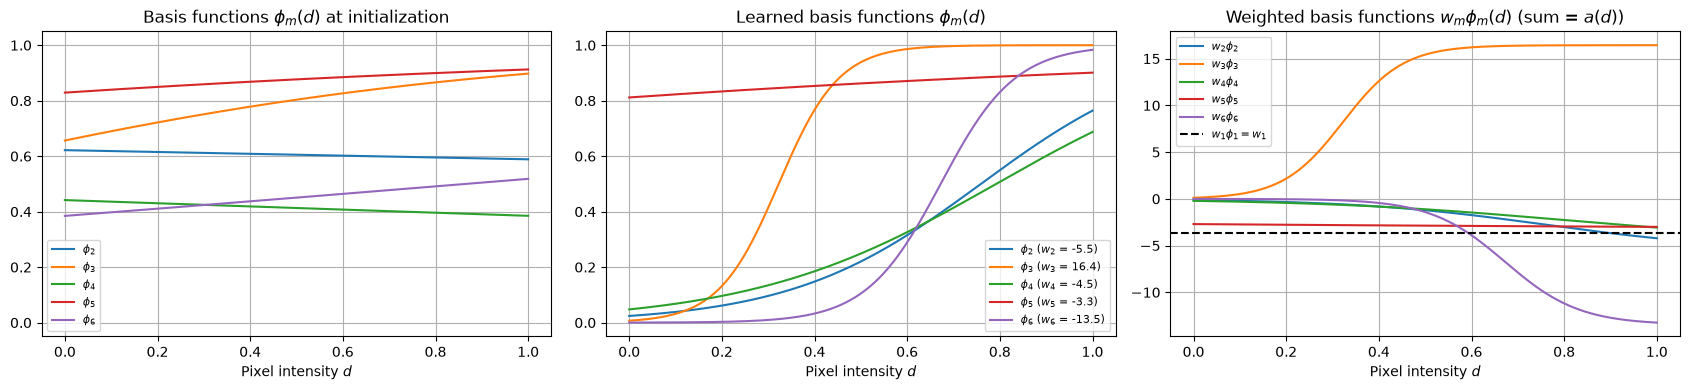

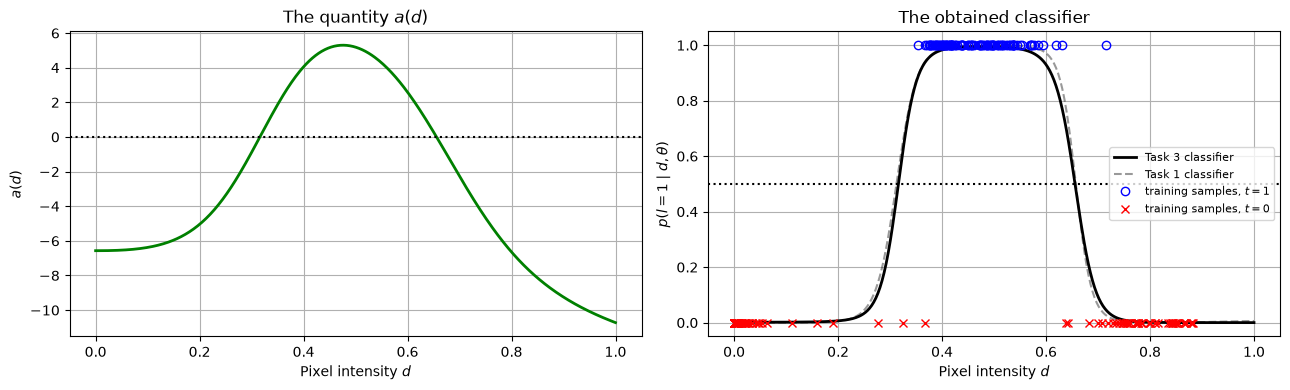

Decision boundaries (a(d) = 0) at d = [0.31 0.66]


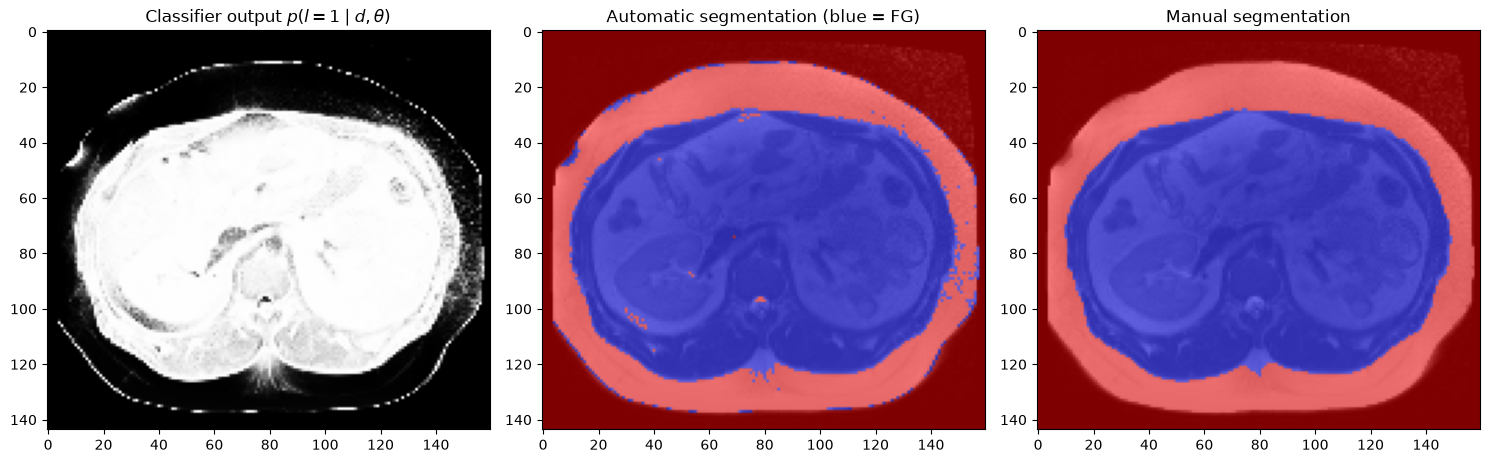

Dice coefficient (test image): 0.982   (Task 1: 0.981)
Mean cross-entropy over the last 500 iterations: Task 3 = 10.8, Task 1 = 10.5


In [6]:
    # (a) Evolution of the cross-entropy (Task 1 shown for comparison)
plt.figure(figsize=(8, 3.8))
plt.plot(cost3, linewidth=0.6, label='Task 3 (adaptive basis functions)')
plt.plot(cost, linewidth=0.6, alpha=0.5, label='Task 1 (fixed cosine basis functions)')
plt.title('Evolution of the cross-entropy')
plt.xlabel('Iteration'); plt.ylabel(r"$E_{N'}(\theta)$")
plt.ylim(0, 150); plt.legend(); plt.grid(True)
plt.show()

# (b) Basis functions phi_m(d): before and after training, and weighted by w_m
d_grid = np.linspace(0, 1, 500)
Phi_init = compute_basis_adaptive(d_grid, beta_init)
Phi_grid = compute_basis_adaptive(d_grid, beta3)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for m in range(2, M + 1):
    axes[0].plot(d_grid, Phi_init[:, m - 1], label=f'$\\phi_{m}$')
    axes[1].plot(d_grid, Phi_grid[:, m - 1], label=f'$\\phi_{m}$ ($w_{m}$ = {w3[m - 1]:.1f})')
    axes[2].plot(d_grid, w3[m - 1] * Phi_grid[:, m - 1], label=f'$w_{m}\\phi_{m}$')
axes[2].axhline(w3[0], color='k', linestyle='--', label=f'$w_1\\phi_1 = w_1$')
axes[0].set_title(r'Basis functions $\phi_m(d)$ at initialization')
axes[1].set_title(r'Learned basis functions $\phi_m(d)$')
axes[2].set_title(r'Weighted basis functions $w_m \phi_m(d)$ (sum = $a(d)$)')
for ax in axes:
    ax.set_xlabel('Pixel intensity $d$'); ax.grid(True); ax.legend(fontsize=8)
axes[0].set_ylim(-0.05, 1.05); axes[1].set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.show()

# (c) The quantity a(d) and the obtained classifier, with the samples of the last iteration
a_grid3 = Phi_grid @ w3
p_grid3 = sigmoid(a_grid3)
fg, bg = t_batch3 == 1, t_batch3 == 0

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(d_grid, a_grid3, 'g', linewidth=2)
axes[0].axhline(0, color='k', linestyle=':')
axes[0].set_title('The quantity $a(d)$')
axes[0].set_xlabel('Pixel intensity $d$'); axes[0].set_ylabel('$a(d)$'); axes[0].grid(True)

axes[1].plot(d_grid, p_grid3, 'k', linewidth=2, label='Task 3 classifier')
axes[1].plot(d_grid, sigmoid(compute_basis_fixed(d_grid, M) @ w), 'k--', alpha=0.4, label='Task 1 classifier')
axes[1].axhline(0.5, color='k', linestyle=':')
axes[1].plot(d_batch3[fg], t_batch3[fg], 'bo', mfc='none', label='training samples, $t=1$')
axes[1].plot(d_batch3[bg], t_batch3[bg], 'rx', label='training samples, $t=0$')
axes[1].set_title('The obtained classifier')
axes[1].set_xlabel('Pixel intensity $d$'); axes[1].set_ylabel(r'$p(l=1 \mid d, \theta)$')
axes[1].legend(loc='center right', fontsize=8); axes[1].grid(True)
plt.tight_layout(); plt.show()

edges3 = d_grid[np.flatnonzero(np.diff((a_grid3 > 0).astype(int)))]
print('Decision boundaries (a(d) = 0) at d =', np.round(edges3, 2))

# (d) Segmentation of the original test image
prob_map_test3 = classifier_adaptive(theta3, TestI.ravel()).reshape(TestI.shape)
pred_seg_test3 = (prob_map_test3 >= 0.5).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].imshow(prob_map_test3, cmap='gray', vmin=0, vmax=1)
axes[0].set_title(r'Classifier output $p(l=1 \mid d, \theta)$')
plt.sca(axes[1]); plotSeg(TestI, pred_seg_test3)
axes[1].set_title('Automatic segmentation (blue = FG)')
plt.sca(axes[2]); plotSeg(TestI, TestS)
axes[2].set_title('Manual segmentation')
plt.tight_layout(); plt.show()

dice3 = 2 * np.sum(pred_seg_test3 * TestS) / (pred_seg_test3.sum() + TestS.sum())
print(f'Dice coefficient (test image): {dice3:.3f}   (Task 1: {dice:.3f})')
print(f'Mean cross-entropy over the last 500 iterations: Task 3 = {cost3[-500:].mean():.1f}, Task 1 = {cost[-500:].mean():.1f}')

### Results and Discussion for Task 3

* **Convergence of stochastic gradient descent:** The cross-entropy again starts at $N' \ln 2 \approx 139$ and converges to a value of $E_{N'} \approx 11$, comparable to Task 1. However, the training behaves quite differently in the beginning: the cross-entropy stays close to its initial value for about 300 iterations and only drops below 20 after roughly 1000 iterations, whereas the Task 1 model reached this level within about 50 iterations. There are two reasons for this slow start. First, with $w_m = 0$ the hidden units have no influence on the output, so in the very first iteration the gradient with respect to the $\beta_{m,j}$ is exactly zero and only the weights are updated. Second, because the $\beta_{m,j}$ are initialized with unit variance, all basis functions are initially very smooth and almost linear over the intensity range $[0, 1]$ (see the left panel). A combination of such functions cannot form the band-pass classifier that is needed, so training first has to make the steps steeper and move them to the right intensities before the cross-entropy can decrease significantly. After this phase, the cross-entropy fluctuates around a stable value, with the same noise level as in Task 1, caused by the random sampling of $N' = 200$ new pixels in each iteration.

* **Learned basis functions:** During training, the basis functions changed from almost flat curves into steps at specific intensities. Their roles can be read from the step locations $d^*_m = -\beta_{m,0}/\beta_{m,1}$ and the weights $w_m$:
  * $\phi_3$ is a sharp rising step at $d \approx 0.32$ with a large positive weight ($w_3 \approx 16.4$). It raises $a(d)$ for intensities above the air and defines the **lower decision boundary**.
  * $\phi_6$ is a sharp step at $d \approx 0.67$ with a large negative weight ($w_6 \approx -13.5$). It lowers $a(d)$ again for the bright fat and defines the **upper decision boundary**.
  * $\phi_2$ and $\phi_4$ are shallow steps around $d \approx 0.76$–$0.79$ with negative weights. They push $a(d)$ further down for the brightest pixels, making the classifier more confident there.
  * $\phi_5$ has its step outside the intensity range ($d^* \approx -1.95$), so it is nearly constant over $[0, 1]$ and effectively acts as an additional bias term together with $w_1$.

  The network has therefore learned, by itself, the structure we anticipated in the theoretical background: the band-pass is built from one rising and one falling step, and the remaining hidden units are only used for fine-tuning or are effectively redundant. This shows that $M - 1 = 5$ hidden units are more than enough for this one-dimensional problem.

* **The quantity $a(d)$ and the obtained classifier:** $a(d)$ is positive only between $d \approx 0.31$ and $d \approx 0.66$, giving exactly the same decision boundaries as the cosine model of Task 1, and the classifier $p(l=1 \mid d, \boldsymbol{\theta})$ almost coincides with the Task 1 classifier. As before, the training samples of the last iteration lie almost entirely on the correct side of the boundaries. One difference is visible outside the band: because the adaptive basis functions are monotonic steps, $a(d)$ is monotonically decreasing for bright intensities, whereas the periodic cosines of Task 1 made $a(d)$ rise again towards $d = 1$. The adaptive model therefore behaves more naturally in intensity ranges with few training samples.

* **Segmentation of the test image:** The segmentation of the original test image is practically identical to that of Task 1, with a Dice coefficient of **0.98** (0.982 vs. 0.981). The remaining errors are the same as before: a thin ring of false positives at the outer edge of the body (partial-volume effect between fat and air), some scattered false positives in the darker parts of the fat layer, and a few false negatives at bright structures inside the abdomen. This is expected: both models learn the same decision rule on the intensity, so they also share the same fundamental limitation of a pixel-wise classifier, which has no access to spatial context.

* **Dependence on the initialization:** Since the cross-entropy is no longer convex in the parameters, the result depends on the random initialization of the $\beta_{m,j}$: a different initialization can lead to a different set of basis functions (e.g. the boundary-defining steps assigned to other hidden units, or a rising step with a negative weight instead of a falling step with a positive weight) that still represents (almost) the same classifier. Many different parameter values can thus represent the same function, which is typical for neural networks.
* **Conclusion:** For a one-dimensional input, adaptive basis functions do not improve the segmentation compared to well-chosen fixed basis functions: both models reach the same decision rule and the same accuracy, and the adaptive model even needs more iterations to converge, has more parameters (16 instead of 6), and has a non-convex training problem. The advantage of adaptive basis functions is that their shape does not have to be designed by hand but is learned from the data, and that their number does not grow exponentially with the input dimension. This becomes essential in the next tasks, where the input consists of two (Task 4) or nine (Task 5) intensities.

## Task 4: Use Neighbour Pixel as second Input Feature

Using the data in the file ```dataForNN_foreBorder_clip1.mat```, re-train and re-apply your classifier, but this time not just based on the intensity in the pixel being classified, but also on that of the pixel in the next row (i.e., the input x is now a vector of dimension $p = 2$). In addition to showing the classifier output on the test image, also include in your report a visualization of the learned basis functions $\phi_m(d)$ in the 2D input space, along with the learned classifier (again in the 2D input space). For the latter, please include a visualization of where the training samples $\{x_i , y_i \}$ are located (cf. the first task).

### Theoretical Background: Two-Dimensional Input (Pixel and Neighbour Below)

#### The segmentation problem
In this task we use the data in `dataForNN_foreBorder_clip1`. The structure to be segmented is no longer a large region, but the **border just outside the body**: a thin line, one to two pixels thick, along the top of the body (about 3 % of all pixels). These border pixels lie in the air, so their intensity is just as dark as that of the surrounding air. A pixel-wise classifier such as the ones of Tasks 1–3 therefore cannot solve this problem: there is no intensity band that contains the border but not the air. What distinguishes a border pixel from an air pixel is its **context**: the pixel directly below a border pixel lies inside the body and is bright, whereas the pixel below an air pixel is dark as well.

#### Input features
We therefore extend the input to a vector of dimension $p = 2$, containing the intensity of the pixel being classified and that of the pixel in the next row (directly below it):

$$
\mathbf{x} = (x_1, x_2)^T = \big(d_{r,c},\; d_{r+1,c}\big)^T ,
$$

where $(r, c)$ are the row and column of the pixel. These features are provided by `getInputFeatures(image, numberOfNeighbors=1)`. For the last image row there is no pixel below; the function then uses $x_2 = 0$ (zero padding).

In the 2D input space the classes occupy different regions:
* **air** (background): both pixels dark, $\mathbf{x} \approx (0, 0)$;
* **inside the body** (background): both pixels bright and similar, so $\mathbf{x}$ lies close to the diagonal $x_1 = x_2$;
* **border** (foreground): the pixel itself is dark while the pixel below is bright, $x_1 \ll x_2$, i.e. the region in the **upper-left** part of the input space, above the diagonal.

The foreground is thus characterised by a large vertical intensity difference $x_2 - x_1$ (a dark-to-bright edge going downwards), which is information that is invisible to a pixel-wise classifier.

#### Model
We use the same network with adaptive basis functions as in Task 3 (Eq. 4.9), now with a two-dimensional input:

$$
\phi_m(\mathbf{x}) =
\begin{cases}
1 & \text{if } m = 1, \\[4pt]
\sigma\big(\beta_{m,1} x_1 + \beta_{m,2} x_2 + \beta_{m,0}\big) & \text{for } m = 2, \dots, M,
\end{cases}
\qquad
p(l = 1 \mid \mathbf{x}, \boldsymbol{\theta}) = \sigma\Big(\sum_{m=1}^{M} w_m \phi_m(\mathbf{x})\Big).
$$

With $M = 6$ the model has $6$ weights $w_m$ and $5 \times 3 = 15$ parameters $\beta_{m,j}$, i.e. $21$ parameters in total. Note that with fixed separable basis functions (products of 1D basis functions, as in Sec. 1.3) we would already need $5^2 = 25$ basis functions in 2D, and the number would grow exponentially with $p$; with adaptive basis functions only the number of $\beta$'s per hidden unit grows, linearly with $p$.

#### Interpretation of the basis functions in 2D
Each hidden unit $\phi_m(\mathbf{x})$ is a smooth **step across a straight line** in the input space:
* the transition ($\phi_m = 0.5$) lies on the line $\beta_{m,1} x_1 + \beta_{m,2} x_2 + \beta_{m,0} = 0$;
* $\phi_m$ increases in the direction of the vector $(\beta_{m,1}, \beta_{m,2})$, which is perpendicular to this line;
* the steepness of the step is set by the length $\|(\beta_{m,1}, \beta_{m,2})\|$.

In the 2D input space each basis function therefore looks like a "ramp" that goes from 0 to 1 across a line. A particularly useful hidden unit for this problem has $\beta_{m,1} \approx -\beta_{m,2}$ with $\beta_{m,2} > 0$: it then responds to $x_2 - x_1$, i.e. it is a **vertical edge detector** (a finite-difference filter) that is active when the pixel below is much brighter than the pixel itself. The output unit combines several such steps; $a(\mathbf{x}) = \sum_m w_m \phi_m(\mathbf{x})$ can thus become positive in a region bounded by several (smoothed) straight lines, such as the upper-left region where the border pixels lie, while remaining negative near the origin (air) and along the diagonal (inside the body).

#### Training and class balance
Training is identical to Tasks 1 and 3: the cross-entropy (Eq. 4.7) is minimised with stochastic gradient descent ($N' = 200$, $\nu' = 0.005$, 5000 iterations), the gradient with respect to all 21 parameters is approximated by finite differences, and we initialise $w_m = 0$ and $\beta_{m,j} \sim \mathcal{N}(0, 1)$.

`getSamples()` again draws 100 foreground and 100 background pixels in every iteration, although the border makes up only about 3 % of the image. The classifier is thus trained as if both classes were equally likely a priori. This is necessary to learn the small class at all, but it also means that the classifier will tend to assign ambiguous pixels to the foreground more often than the true class proportions would justify, which may lead to a somewhat thicker border or isolated false positives in the segmentation.

#### Expected limitations
Even with the extra feature, not all pixels can be separated. Where the border is not horizontal (e.g. on the steep sides of the body), the pixel below a border pixel can itself be a border pixel, so its feature vector lies close to the air cluster. Moreover, since the network only looks *downwards*, any dark pixel directly above a brighter one (noise in the air, or edges inside the body) looks like a border pixel.

#### What we visualise
For the trained model we show the evolution of the cross-entropy, the classifier output on the test image and the resulting segmentation, the learned basis functions $\phi_m(\mathbf{x})$ as images over the 2D input space $[0, 1]^2$, and the learned classifier $p(l = 1 \mid \mathbf{x}, \boldsymbol{\theta})$ in the same 2D input space, together with the location of the training samples of the last iteration (foreground and background).

### Data exploration
We first load the data of `dataForNN_foreBorder_clip1` and show all training pixels in the 2D input space $\mathbf{x} = (x_1, x_2)$, where $x_1$ is the intensity of the pixel itself and $x_2$ that of the pixel directly below it.

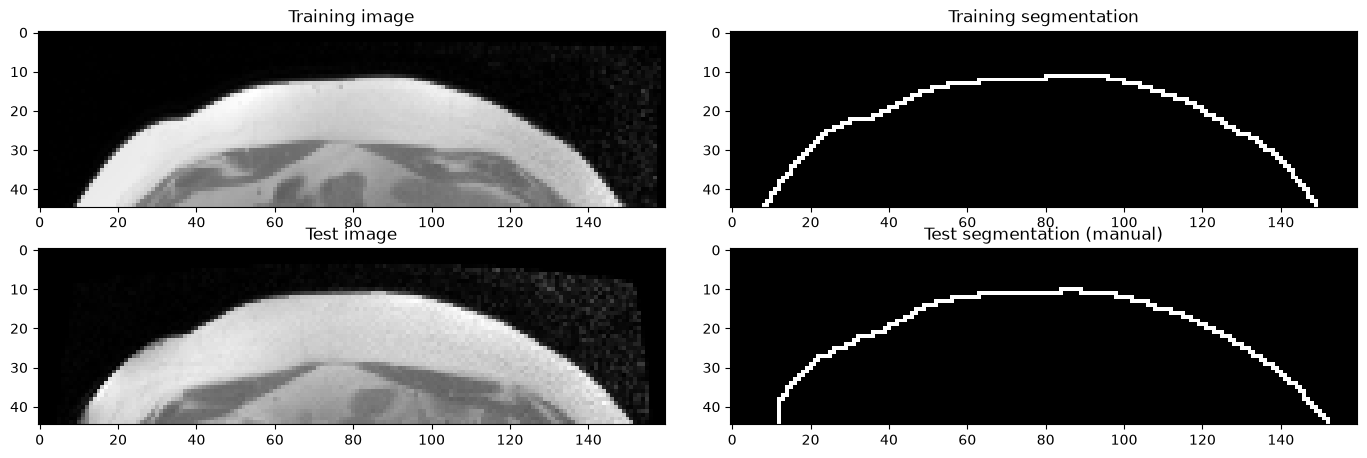

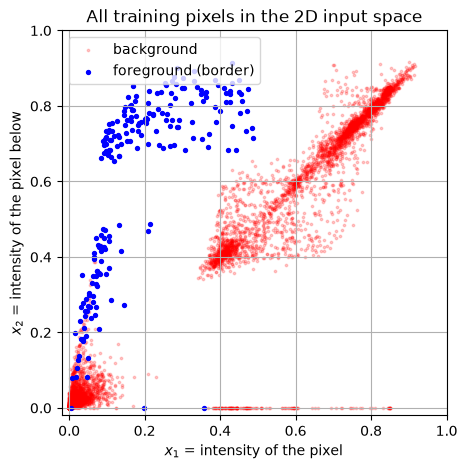

Foreground fraction in the training image: 0.029


In [7]:
# Task 4: two input features (pixel + pixel in the next row) 
clip1 = np.load('dataForNN_foreBorder_clip1.npy', allow_pickle=True).tolist()
TI4, TS4 = clip1['trainingImage'], clip1['trainingSegmentation']
TestI4, TestS4 = clip1['testImage'], clip1['testSegmentation']

numberOfNeighbors4 = 1                                    
featTrain4 = getInputFeatures(TI4, numberOfNeighbors4)    
featTest4 = getInputFeatures(TestI4, numberOfNeighbors4)
p4 = featTrain4.shape[2]

# Data exploration: training/test images and the training pixels in the 2D input space
fig, axes = plt.subplots(2, 2, figsize=(14, 4.5))
axes[0, 0].imshow(TI4, cmap='gray');     axes[0, 0].set_title('Training image')
axes[0, 1].imshow(TS4, cmap='gray');     axes[0, 1].set_title('Training segmentation')
axes[1, 0].imshow(TestI4, cmap='gray');  axes[1, 0].set_title('Test image')
axes[1, 1].imshow(TestS4, cmap='gray');  axes[1, 1].set_title('Test segmentation (manual)')
plt.tight_layout(); plt.show()

X_all, t_all = featTrain4.reshape(-1, p4), TS4.ravel()
plt.figure(figsize=(5.5, 5))
plt.scatter(X_all[t_all == 0, 0], X_all[t_all == 0, 1], s=3, c='r', alpha=0.2, label='background')
plt.scatter(X_all[t_all == 1, 0], X_all[t_all == 1, 1], s=8, c='b', label='foreground (border)')
plt.xlabel('$x_1$ = intensity of the pixel'); plt.ylabel('$x_2$ = intensity of the pixel below')
plt.title('All training pixels in the 2D input space')
plt.axis('square'); plt.xlim(-0.02, 1); plt.ylim(-0.02, 1); plt.legend(); plt.grid(True)
plt.show()
print(f'Foreground fraction in the training image: {TS4.mean():.3f}')

### Model and training
The network of Task 3 is generalised to a $p$-dimensional input: each hidden unit now has $p + 1$ parameters $\beta_{m,0}, \dots, \beta_{m,p}$. The functions are written for general $p$ so that they can be reused in Task 5. The parameters are initialised with $w_m = 0$ and $\beta_{m,j} \sim \mathcal{N}(0, 1)$ and trained with stochastic gradient descent and finite differences as before.

In [8]:
# Model with adaptive basis functions for a p-dimensional input 
# theta = [w_1..w_M, beta_2 (p+1 values), ..., beta_M (p+1 values)],  beta_m = [beta_{m,0}, beta_{m,1}, ..., beta_{m,p}]

def unpack_nn(theta, M, p):
    w = theta[:M]
    beta = theta[M:].reshape(M - 1, p + 1)
    return w, beta

def compute_basis_nn(X, beta):
    """X: (N, p) inputs, beta: (M-1, p+1). Returns Phi (N, M) with phi_1 = 1."""
    hidden = sigmoid(X @ beta[:, 1:].T + beta[:, 0])        # (N, M-1)
    return np.hstack([np.ones((X.shape[0], 1)), hidden])

def classifier_nn(theta, X, M, p):
    w, beta = unpack_nn(theta, M, p)
    return sigmoid(compute_basis_nn(X, beta) @ w)

def compute_loss_nn(theta, X, t, M, p):
    y = classifier_nn(theta, X, M, p)
    eps = 1e-12
    return -np.sum(t * np.log(y + eps) + (1.0 - t) * np.log(1.0 - y + eps))

def train_nn(featureImage, segmentation, M, numIter, noOfSamples, stepSize, seed=42, delta=1e-5):
    p = featureImage.shape[2]
    np.random.seed(seed)
    theta = np.concatenate([np.zeros(M), np.random.randn((M - 1) * (p + 1))])   # w = 0, beta ~ N(0,1)
    cost = np.zeros(numIter)
    for i in range(numIter):
        X, t, rowAndCol = getSamples(featureImage, segmentation, noOfSamples)
        cost[i] = compute_loss_nn(theta, X, t, M, p)
        gradient = np.zeros_like(theta)
        for n in range(theta.size):
            theta_perturbed = theta.copy()
            theta_perturbed[n] += delta
            newCost = compute_loss_nn(theta_perturbed, X, t, M, p)
            gradient[n] = (newCost - cost[i]) / delta
        theta = theta - stepSize * gradient
    return theta, cost, (X, t, rowAndCol)

# Train
theta4, cost4, (X_batch4, t_batch4, rowAndCol4) = train_nn(featTrain4, TS4, M, numIter, noOfSamples, vm)
w4, beta4 = unpack_nn(theta4, M, p4)

print('Weights w_1..w_M:', np.round(w4, 2))
print('\n m   beta_m0   beta_m1   beta_m2    w_m')
for m in range(2, M + 1):
    print(f'{m:2d}  {beta4[m-2, 0]:8.2f}  {beta4[m-2, 1]:8.2f}  {beta4[m-2, 2]:8.2f}  {w4[m-1]:7.2f}')

Weights w_1..w_M: [ 0.88 11.72  2.94 -7.23  0.24 -6.61]

 m   beta_m0   beta_m1   beta_m2    w_m
 2     -1.46    -10.66      8.88    11.72
 3      1.39     -1.72     -2.18     2.94
 4      1.81      7.38     -5.62    -7.23
 5      0.40      0.61     -0.77     0.24
 6     -0.29     -6.28     -7.65    -6.61


### Visualizations for Task 4
We show (a) the evolution of the cross-entropy; (b) the classifier output on the test image and the resulting segmentation, compared with the manual segmentation; (c) the learned basis functions $\phi_m(\mathbf{x})$ as images over the 2D input space, where the white line marks $\phi_m = 0.5$; and (d) the learned classifier in the 2D input space, with the decision boundary $p = 0.5$ in yellow and the training samples of the last iteration, together with the location of these samples in the training image.

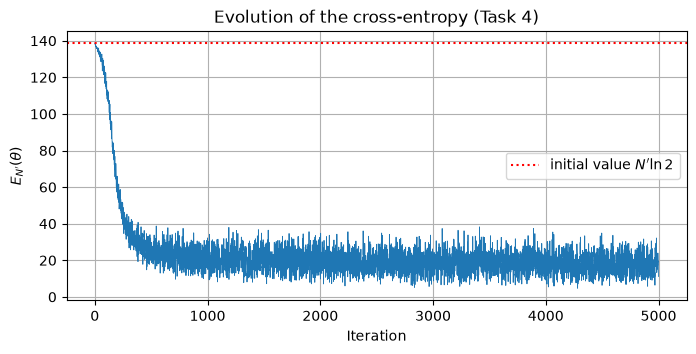

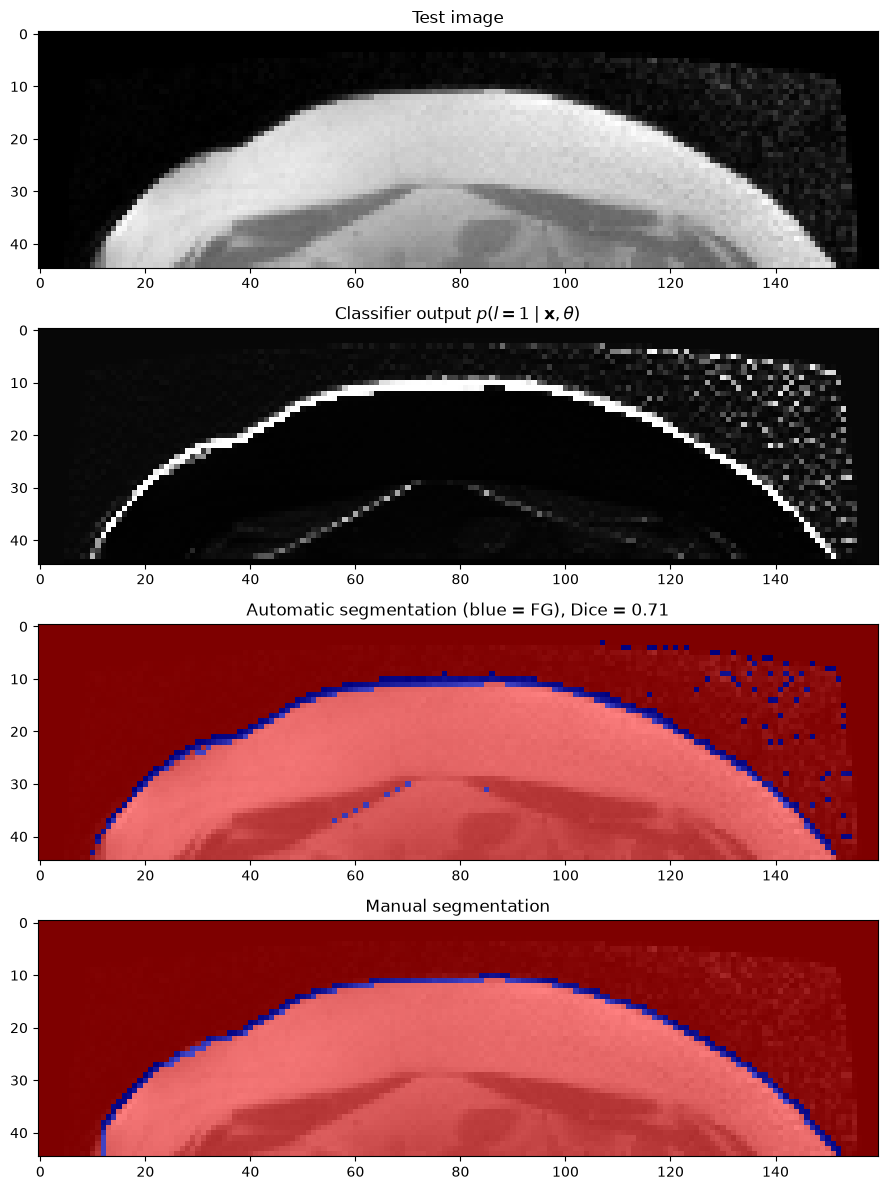

Dice coefficient (test image): 0.709   FP = 130, FN = 23, manual FG pixels = 209


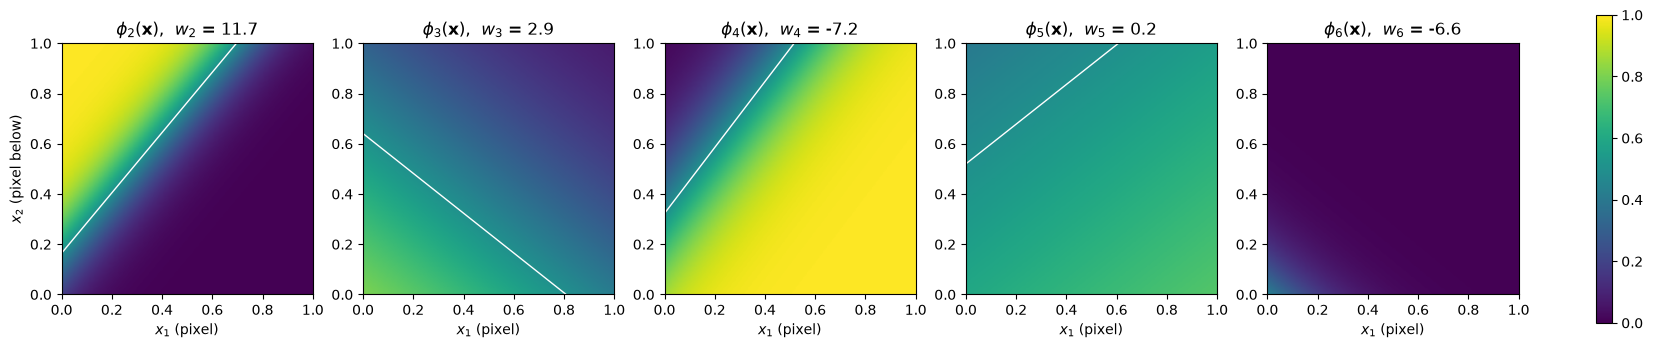

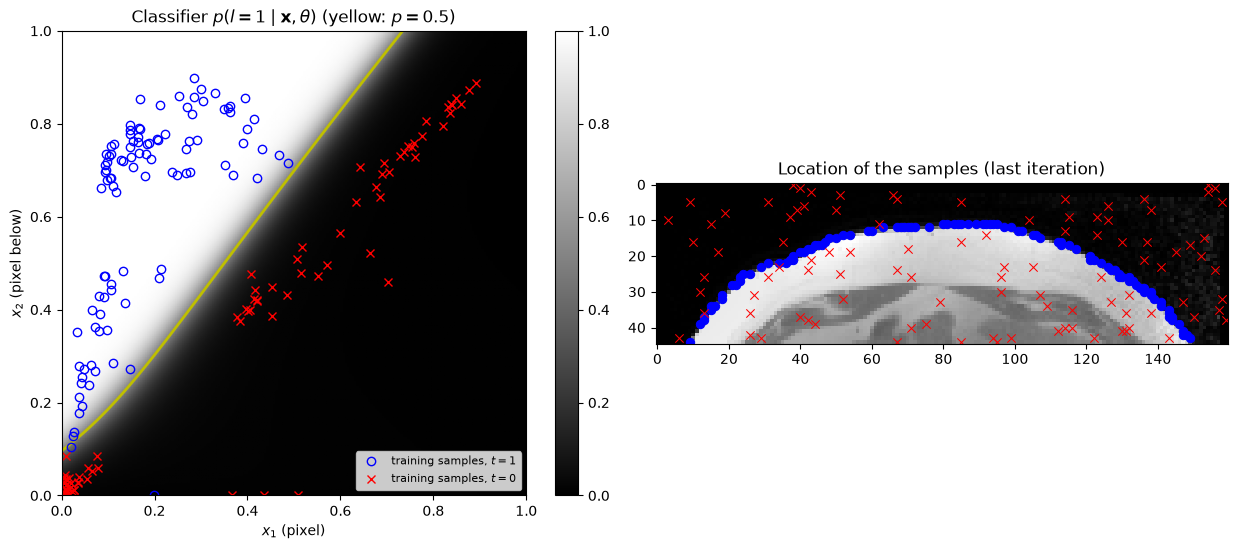

In [9]:
# (a) Evolution of the cross-entropy
plt.figure(figsize=(8, 3.5))
plt.plot(cost4, linewidth=0.6)
plt.axhline(noOfSamples * np.log(2), color='r', linestyle=':', label=r"initial value $N'\ln 2$")
plt.title('Evolution of the cross-entropy (Task 4)')
plt.xlabel('Iteration'); plt.ylabel(r"$E_{N'}(\theta)$"); plt.legend(); plt.grid(True)
plt.show()

# (b) Classifier output and segmentation of the test image
prob_map_test4 = classifier_nn(theta4, featTest4.reshape(-1, p4), M, p4).reshape(TestI4.shape)
pred_seg_test4 = (prob_map_test4 >= 0.5).astype(float)
dice4 = 2 * np.sum(pred_seg_test4 * TestS4) / (pred_seg_test4.sum() + TestS4.sum())

fig, axes = plt.subplots(4, 1, figsize=(10, 12))
axes[0].imshow(TestI4, cmap='gray');                        axes[0].set_title('Test image')
axes[1].imshow(prob_map_test4, cmap='gray', vmin=0, vmax=1); axes[1].set_title(r'Classifier output $p(l=1 \mid \mathbf{x}, \theta)$')
plt.sca(axes[2]); plotSeg(TestI4, pred_seg_test4);         axes[2].set_title(f'Automatic segmentation (blue = FG), Dice = {dice4:.2f}')
plt.sca(axes[3]); plotSeg(TestI4, TestS4);                 axes[3].set_title('Manual segmentation')
plt.tight_layout(); plt.show()

fp4 = np.sum((pred_seg_test4 == 1) & (TestS4 == 0)); fn4 = np.sum((pred_seg_test4 == 0) & (TestS4 == 1))
print(f'Dice coefficient (test image): {dice4:.3f}   FP = {fp4}, FN = {fn4}, manual FG pixels = {int(TestS4.sum())}')

# Grid over the 2D input space
g = np.linspace(0, 1, 201)
G1, G2 = np.meshgrid(g, g)                       # G1 = x1 (pixel), G2 = x2 (pixel below)
X_grid = np.column_stack([G1.ravel(), G2.ravel()])
Phi_grid4 = compute_basis_nn(X_grid, beta4)

# (c) Learned basis functions phi_m(x) in the 2D input space
fig, axes = plt.subplots(1, M - 1, figsize=(4 * (M - 1), 4))
for m in range(2, M + 1):
    ax = axes[m - 2]
    im = ax.imshow(Phi_grid4[:, m - 1].reshape(G1.shape), origin='lower', extent=[0, 1, 0, 1], cmap='viridis', vmin=0, vmax=1)
    ax.contour(G1, G2, Phi_grid4[:, m - 1].reshape(G1.shape), levels=[0.5], colors='w', linewidths=1)
    ax.set_title(f'$\\phi_{m}(\\mathbf{{x}})$,  $w_{m}$ = {w4[m - 1]:.1f}')
    ax.set_xlabel('$x_1$ (pixel)')
    if m == 2: ax.set_ylabel('$x_2$ (pixel below)')
fig.colorbar(im, ax=axes, fraction=0.01)
plt.show()

# (d) Learned classifier in the 2D input space, with the training samples of the last iteration
P_grid4 = sigmoid(Phi_grid4 @ w4).reshape(G1.shape)
fg, bg = t_batch4 == 1, t_batch4 == 0

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
im = axes[0].imshow(P_grid4, origin='lower', extent=[0, 1, 0, 1], cmap='gray', vmin=0, vmax=1)
axes[0].contour(G1, G2, P_grid4, levels=[0.5], colors='y', linewidths=2)
axes[0].plot(X_batch4[fg, 0], X_batch4[fg, 1], 'bo', mfc='none', label='training samples, $t=1$')
axes[0].plot(X_batch4[bg, 0], X_batch4[bg, 1], 'rx', label='training samples, $t=0$')
axes[0].set_xlabel('$x_1$ (pixel)'); axes[0].set_ylabel('$x_2$ (pixel below)')
axes[0].set_title(r'Classifier $p(l=1 \mid \mathbf{x}, \theta)$ (yellow: $p = 0.5$)')
axes[0].legend(loc='lower right', fontsize=8)
fig.colorbar(im, ax=axes[0], fraction=0.046)

plt.sca(axes[1])
showLocationOfSamples(TI4, rowAndCol4, t_batch4)
axes[1].set_title("Location of the samples (last iteration)")
plt.tight_layout(); plt.show()

### Results and Discussion for Task 4

* **2D input space:** The scatter plot confirms the theory: air lies near the origin, the inside of the body along the diagonal $x_1 \approx x_2$, and the border pixels in the upper-left region (dark pixel above a bright one). The horizontal line at $x_2 = 0$ is the last image row (zero padding). Border and air cannot be separated by $x_1$ alone, but they are well separated in 2D.

* **Convergence:** The cross-entropy drops from $N' \ln 2 \approx 139$ to about 20 within ~300 iterations and then stays stable. It is higher than in Tasks 1–3 (~10) because some border pixels lie close to the air cluster, so the classes overlap more.

* **Learned basis functions:** Each hidden unit is a smooth step across a line in the input space.
  * $\phi_2$ ($w_2 \approx 11.7$, $\beta \approx (-10.7, 8.9)$) responds to $x_2 - x_1$: a **vertical edge detector** and the main unit detecting the border.
  * $\phi_4$ ($w_4 \approx -7.2$) is a step along almost the same direction and sharpens the boundary.
  * $\phi_6$ ($w_6 \approx -6.6$) is only active near the origin and **suppresses the air**.
  * $\phi_3$ and $\phi_5$ contribute little.

* **Classifier in 2D:** The decision boundary ($p = 0.5$) is roughly a straight line from $(0, 0.1)$ to $(0.75, 1)$. Pixels much darker than the pixel below them are classified as border; the air and the body as background. The training samples are almost perfectly separated, except for a few foreground samples near the origin.

* **Segmentation of the test image:** The network finds the border along the whole top of the body, which a pixel-wise classifier could not do. The Dice coefficient is **0.71** (130 FP, 23 FN, 209 border pixels); since the structure is so thin, every error weighs heavily. The errors are:
  * **border too thick**: about half of the false positives are adjacent to the manual border (partial-volume effect);
  * **noise in the air**: a dark noise pixel above a brighter one looks like a border pixel (most other false positives, top right);
  * **internal edges**: a few pixels on a dark-to-bright edge inside the body;
  * **steep flanks (FN)**: where the border runs diagonally or vertically, the pixel below is often also border, so the feature vector lies near the air cluster.

* **Conclusion:** Adding one neighbouring pixel makes the problem solvable, because the network can now use the local intensity *change* instead of the absolute intensity, and its hidden units act as simple image filters. The remaining errors come from the very limited context (looking only one pixel down), which motivates the $3 \times 3$ patches of Task 5.

## Task 5: Use 8 Neighbours as Input Features

Using the data in the file ```dataForNN_foreBorder_clip0.mat```, re-train and re-apply the same classifier, but now using 3 × 3 patches as input, i.e., the input $x$ is now a vector of dimension $p = 9$. In your report you should include the classifier output on the test image, as well as the feature maps and the corresponding model weights $\{ \beta_{m,j} \}^{p}_{j=1}$ as visualized in Fig. 4.5(d) and Fig. 4.5(e), respectively.

## Task 6: (for the enthusiastic student)

In order to provide a more challenging task to the neural network, do task 4 again but this time using the data in the file ```dataForNN_foreBorder_clip0.mat```. Concentrate on the visualization of the learned basis functions and especially that of the classifier with respect to the training samples. Can you explain why this scenario is more challenging than the one of task 4? You can also try to add another hidden layer in the network – what do the basis functions look like now?